In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> T4 GPU, then run again.")

CUDA available: True
GPU: Tesla T4


In [2]:
!pip -q install ultralytics

In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR    = '/content/drive/MyDrive/cleanops'
TACO_ZIP     = f'{DRIVE_DIR}/TACO.zip'
CLEAN_SCRIPT = f'{DRIVE_DIR}/clean_taco.py'

missing = [p for p in (TACO_ZIP, CLEAN_SCRIPT) if not os.path.exists(p)]
for p in (TACO_ZIP, CLEAN_SCRIPT):
    print(('OK       ' if os.path.exists(p) else 'MISSING  ') + p)
if missing:
    raise FileNotFoundError(f'Upload these to Google Drive (My Drive/cleanops) first: {missing}')

size_mb = os.path.getsize(TACO_ZIP) / 1e6
print(f'TACO.zip size: {size_mb:.0f} MB  (the real Kaggle dataset is about 243 MB)')
assert size_mb > 100

Mounted at /content/drive
OK       /content/drive/MyDrive/cleanops/TACO.zip
OK       /content/drive/MyDrive/cleanops/clean_taco.py
TACO.zip size: 243 MB  (the real Kaggle dataset is about 243 MB)


In [16]:
import zipfile
from pathlib import Path

RAW = Path('/content/TACO_raw')
if not RAW.exists():
    with zipfile.ZipFile(TACO_ZIP) as z:
        z.extractall(RAW)
found = sorted(RAW.rglob('data.yaml'))
if not found:
    raise FileNotFoundError(f'data.yaml not found inside {TACO_ZIP}. Is this the Kaggle "TACO Dataset YOLO Format" zip?')
TACO_SRC = found[0].parent
print('TACO folder:', TACO_SRC)

TACO folder: /content/TACO_raw


In [14]:
!python "{CLEAN_SCRIPT}" --src "{TACO_SRC}" --out /content/TACO_clean --report /content/TACO_clean_report.json

[1/5] Auditing /content/TACO_raw  (18 classes)
      kept 6004 images; defects: {'degenerate_box_dropped': 40}
[2/5] Fingerprinting images (hamming<=0) ...
      3665 distinct photos among 6004 images; leakage into valid/test: {'valid': {'leaked_images': 421, 'total_images': 1704, 'share': 0.2471}, 'test': {'leaked_images': 42, 'total_images': 100, 'share': 0.42}}
[3/5] Split mode: regroup
[4/5] Charts / report
      report -> /content/TACO_clean_report.json
[5/5] Exporting cleaned dataset -> /content/TACO_clean
Done.  after-split image counts: {'train': 4817, 'valid': 580, 'test': 607} | groups still crossing splits: 0


In [15]:
from pathlib import Path

TACO_ZIP = Path('/content/drive/MyDrive/cleanops/TACO.zip')

print("File exists:", TACO_ZIP.exists())

File exists: True


In [17]:
from pathlib import Path
import yaml

CLEAN = Path('/content/TACO_clean')
taco_names = yaml.safe_load((CLEAN / 'data.yaml').read_text())['names']
print(len(taco_names), 'TACO classes:', taco_names)


def map_to_cleanops(category_name):

    name = category_name.lower()


    if any(word in name for word in ["plastic", "polypropylene", "styrofoam", "foam", "polystyrene", "six pack rings"]):
        return "Plastic"

    if any(word in name for word in ["paper", "carton", "cardboard", "magazine", "tissue", "pizza box", "egg carton"]):
        return "Paper/Cardboard"

    if "glass" in name:
        return "Glass"

    if any(word in name for word in ["metal", "aluminium", "aluminum", "can", "aerosol", "battery", "pop tab"]):
        return "Metal"

    return "Organic/Trash"


MERGED_CLASS_OVERRIDES = {
    'Bottle':     'Plastic',
    'Bottle cap': 'Plastic',
    'Cup':        'Plastic',
    'Lid':        'Plastic',
    'Straw':      'Plastic', }

CLASS_MAP = {n: MERGED_CLASS_OVERRIDES.get(n, map_to_cleanops(n)) for n in taco_names}
CLASS_ORDER = ['Plastic', 'Paper/Cardboard', 'Glass', 'Metal', 'Organic/Trash']


if CLASS_MAP is not None:
    print('TACO class -> CleanOps class')
    for n in taco_names:
        how = 'merged-class override' if n in MERGED_CLASS_OVERRIDES else 'Task-3 rule'
        print(f'  {n:24s} -> {CLASS_MAP[n]:16s} ({how})')

marker = CLEAN / '.class_map_applied'
if marker.exists():
    raise RuntimeError('Mapping was already applied to these labels. Re-run section 3 (cleaning) first, then this cell.')

if CLASS_MAP is None:
    new_names = list(taco_names)
    old2new = {i: i for i in range(len(taco_names))}
else:
    missing = [n for n in taco_names if n not in CLASS_MAP]
    unknown = [k for k in CLASS_MAP if k not in taco_names]
    assert not missing, f'Add these TACO classes to CLASS_MAP (use None to drop): {missing}'
    assert not unknown, f'These keys are not TACO class names (check spelling): {unknown}'
    targets = {t for t in CLASS_MAP.values() if t is not None}
    new_names = [c for c in CLASS_ORDER if c in targets] + sorted(targets - set(CLASS_ORDER))
    old2new = {i: (None if CLASS_MAP[n] is None else new_names.index(CLASS_MAP[n]))
               for i, n in enumerate(taco_names)}

removed_images = 0
if CLASS_MAP is not None:
    for split in ('train', 'valid', 'test'):
        for lbl in sorted((CLEAN / split / 'labels').glob('*.txt')):
            out, seen = [], set()
            for line in lbl.read_text().splitlines():
                p = line.split()
                if len(p) != 5:
                    continue
                new_id = old2new[int(p[0])]
                if new_id is None:
                    continue
                key = (new_id, *p[1:])
                if key in seen:
                    continue
                seen.add(key)
                out.append(' '.join([str(new_id), *p[1:]]))
            if out:
                lbl.write_text('\n'.join(out) + '\n')
            else:
                lbl.unlink()
                for img in (CLEAN / split / 'images').glob(lbl.stem + '.*'):
                    img.unlink()
                removed_images += 1
marker.write_text('applied')

data_cfg = {'path': str(CLEAN), 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
            'names': {i: n for i, n in enumerate(new_names)}}
Path('/content/cleanops_data.yaml').write_text(yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True))

print(f'Classes used for training ({len(new_names)}):', new_names)
print('Images removed because all their boxes were dropped:', removed_images)
print(Path('/content/cleanops_data.yaml').read_text())

18 TACO classes: ['Aluminium foil', 'Bottle cap', 'Bottle', 'Broken glass', 'Can', 'Carton', 'Cigarette', 'Cup', 'Lid', 'Other litter', 'Other plastic', 'Paper', 'Plastic bag - wrapper', 'Plastic container', 'Pop tab', 'Straw', 'Styrofoam piece', 'Unlabeled litter']
TACO class -> CleanOps class
  Aluminium foil           -> Metal            (Task-3 rule)
  Bottle cap               -> Plastic          (merged-class override)
  Bottle                   -> Plastic          (merged-class override)
  Broken glass             -> Glass            (Task-3 rule)
  Can                      -> Metal            (Task-3 rule)
  Carton                   -> Paper/Cardboard  (Task-3 rule)
  Cigarette                -> Organic/Trash    (Task-3 rule)
  Cup                      -> Plastic          (merged-class override)
  Lid                      -> Plastic          (merged-class override)
  Other litter             -> Organic/Trash    (Task-3 rule)
  Other plastic            -> Plastic          (Task-3

In [18]:
from collections import Counter

for split in ('train', 'valid', 'test'):
    n_img = len(list((CLEAN / split / 'images').glob('*')))
    cnt = Counter()
    for lbl in (CLEAN / split / 'labels').glob('*.txt'):
        for line in lbl.read_text().splitlines():
            if line.strip():
                cnt[int(line.split()[0])] += 1
    print(f'{split:5s}: {n_img} images, {sum(cnt.values())} boxes')
    if split == 'train':
        for i, n in enumerate(new_names):
            print(f'        {n:24s} {cnt[i]}')

train: 4817 images, 14684 boxes
        Plastic                  7496
        Paper/Cardboard          1207
        Glass                    452
        Metal                    1251
        Organic/Trash            4278
valid: 580 images, 1929 boxes
test : 607 images, 1821 boxes


In [20]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [21]:
import os, json
from ultralytics import YOLO

import torch
assert torch.cuda.is_available(), 'No GPU. In Colab: Runtime -> Change runtime type -> T4 GPU, then run again from the top.'

os.chdir('/content')                     # 'cleanops_data.yaml' is resolved from here

# 1. Initialize YOLOv8 nano model
model = YOLO('yolov8n.pt')

# 2. Train on cleaned TACO dataset
results = model.train(
    data='cleanops_data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    name='cleanops_yolov8n'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=cleanops_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

In [22]:
import shutil
from pathlib import Path

os.makedirs('ai/models', exist_ok=True)

save_dir = Path(model.trainer.save_dir)
shutil.copy(save_dir / 'weights' / 'best.pt', 'ai/models/yolov8n_cleanops_best.pt')

metrics = model.val()
summary = {
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr)
}
with open('ai/models/metrics.json', 'w') as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1772.8±786.6 MB/s, size: 38.1 KB)
val: Scanning /content/TACO_clean/valid/labels.cache... 580 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 580/580 128.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 5.0it/s 7.4s
                   all        580       1929      0.505      0.394      0.392      0.275
               Plastic        466       1001      0.681       0.52      0.553      0.383
       Paper/Cardboard        104        152      0.495      0.503      0.497       0.37
                 Glass         12         54       0.17      0.148     0.0893     0.0456
                 Metal         86        162      0.679      0.636      0.617      0.472
         Organic/Trash        211        560

In [23]:
test_metrics = model.val(split='test')
print('TEST  mAP50    :', round(float(test_metrics.box.map50), 4))
print('TEST  mAP50-95 :', round(float(test_metrics.box.map), 4))
print('TEST  precision:', round(float(test_metrics.box.mp), 4))
print('TEST  recall   :', round(float(test_metrics.box.mr), 4))

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1337.1±687.4 MB/s, size: 38.8 KB)
val: Scanning /content/TACO_clean/test/labels... 607 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 607/607 2.1Kit/s 0.3s
val: New cache created: /content/TACO_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 3.1it/s 12.1s
                   all        607       1821      0.537      0.426      0.421      0.317
               Plastic        461        943      0.669      0.632      0.651      0.469
       Paper/Cardboard        119        153      0.641      0.513      0.543      0.436
                 Glass         12         44      0.213      0.227      0.107     0.0485
                 Metal         93        156      0.708      0.596      0.634  


image 1/1 /content/sample_street_waste.jpg: 640x640 2 Plastics, 2 Metals, 12.5ms
Speed: 1.7ms preprocess, 12.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Predictions saved in: /content/runs/detect/predict
Detections: [('Plastic', 0.85), ('Plastic', 0.84), ('Metal', 0.83), ('Metal', 0.81)]


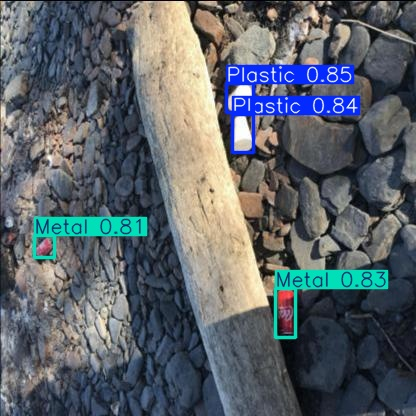

In [24]:
import glob
from IPython.display import Image, display

if not os.path.exists('sample_street_waste.jpg'):
    first_test_image = sorted(glob.glob('/content/TACO_clean/test/images/*'))[0]
    shutil.copy(first_test_image, 'sample_street_waste.jpg')

model = YOLO('ai/models/yolov8n_cleanops_best.pt')
results = model.predict(source='sample_street_waste.jpg', save=True)

out_dir = Path(results[0].save_dir)
saved = sorted(out_dir.glob('*.jpg'))[0]
print('Predictions saved in:', out_dir)
print('Detections:', [(model.names[int(c)], round(float(s), 2)) for c, s in zip(results[0].boxes.cls, results[0].boxes.conf)])
display(Image(filename=str(saved)))

In [25]:
print(open('ai/models/metrics.json').read())

{
    "mAP50": 0.3915721526741949,
    "mAP50-95": 0.2747849864758301,
    "precision": 0.5048935291197612,
    "recall": 0.39354009046253274
}


In [26]:
import shutil
from google.colab import files

shutil.make_archive('/content/cleanops_outputs', 'zip', root_dir='/content', base_dir='ai')
shutil.copy('/content/cleanops_outputs.zip', f'{DRIVE_DIR}/cleanops_outputs.zip')
files.download('/content/cleanops_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>